# 1. Carga o adquisición de datos

En este notebook cargamos el conjunto de datos **EuroSAT (versión RGB)** (Helber et al., 2019). Contiene 27,000 imágenes satelitales tomadas por Sentinel-2 de 64×64 píxeles en 10 clases de uso del suelo: `AnnualCrop`, `Forest`, `HerbaceousVegetation`, `Highway`, `Industrial`, `Pasture`, `PermanentCrop`, `Residential`, `River` y `SeaLake`.

Importamos las librerías necesarias.

In [1]:
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
from PIL import Image

Descargamos el archivo `EuroSAT_RGB.zip` desde el repositorio oficial en Zenodo. Si llega a fallar la conexión directa, usamos Hugging Face Hub como respaldo.

In [2]:
DATA_DIR = Path("data/raw")
DATASET_DIR = DATA_DIR / "EuroSAT_RGB"
ZIP_PATH = DATA_DIR / "EuroSAT_RGB.zip"
ZENODO_URL = "https://zenodo.org/records/7711810/files/EuroSAT_RGB.zip?download=1"

if DATASET_DIR.exists() and any(DATASET_DIR.iterdir()):
    print(f"El dataset ya está en {DATASET_DIR}, se omite la descarga.")
else:
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    try:
        if not ZIP_PATH.exists():
            print("Descargando EuroSAT_RGB.zip desde Zenodo...")
            urllib.request.urlretrieve(ZENODO_URL, ZIP_PATH)

        print("Descomprimiendo archivos...")
        with zipfile.ZipFile(ZIP_PATH, "r") as zf:
            zf.extractall(DATA_DIR)
        print("Datos descargados y extraídos desde Zenodo.")
    except Exception as e:
        print(f"No se pudo descargar desde Zenodo ({type(e).__name__}); se usará Hugging Face Hub.")
        from datasets import load_dataset

        ds = load_dataset("blanchon/EuroSAT_RGB")
        nombres_clases = ds["train"].features["label"].names
        for split in ds:
            for idx, fila in enumerate(ds[split]):
                clase = nombres_clases[fila["label"]]
                carpeta = DATASET_DIR / clase
                carpeta.mkdir(parents=True, exist_ok=True)
                fila["image"].save(carpeta / f"{split}_{idx}.jpg")
        print("Datos descargados desde Hugging Face Hub.")

ruta_dataset = DATASET_DIR if DATASET_DIR.exists() else DATA_DIR
print("Ruta de trabajo:", ruta_dataset)

Descargando EuroSAT_RGB.zip desde Zenodo...
Descomprimiendo archivos...
Datos descargados y extraídos desde Zenodo.
Ruta de trabajo: data/raw/EuroSAT_RGB


Revisamos cuántas clases e imágenes hay en total y verificamos rápidamente el formato en una muestra.

In [3]:
clases = sorted([d.name for d in ruta_dataset.iterdir() if d.is_dir()])
print(f"Número de clases: {len(clases)}")

total = 0
fuera_de_formato = 0

for clase in clases:
    imagenes = list((ruta_dataset / clase).glob("*.jpg"))
    total += len(imagenes)
    print(f"  {clase}: {len(imagenes)} imágenes")

    for img_path in imagenes[:10]:
        with Image.open(img_path) as img:
            if img.size != (64, 64) or img.mode != "RGB":
                fuera_de_formato += 1

print(f"\nTotal de imágenes: {total}")
print(f"Imágenes fuera de formato (64x64 RGB) en la muestra: {fuera_de_formato}")

Número de clases: 10
  AnnualCrop: 3000 imágenes
  Forest: 3000 imágenes
  HerbaceousVegetation: 3000 imágenes
  Highway: 2500 imágenes
  Industrial: 2500 imágenes
  Pasture: 2000 imágenes
  PermanentCrop: 2500 imágenes
  Residential: 3000 imágenes
  River: 2500 imágenes
  SeaLake: 3000 imágenes

Total de imágenes: 27000
Imágenes fuera de formato (64x64 RGB) en la muestra: 0


Mostramos una imagen de ejemplo por cada clase para confirmar que se leen correctamente.

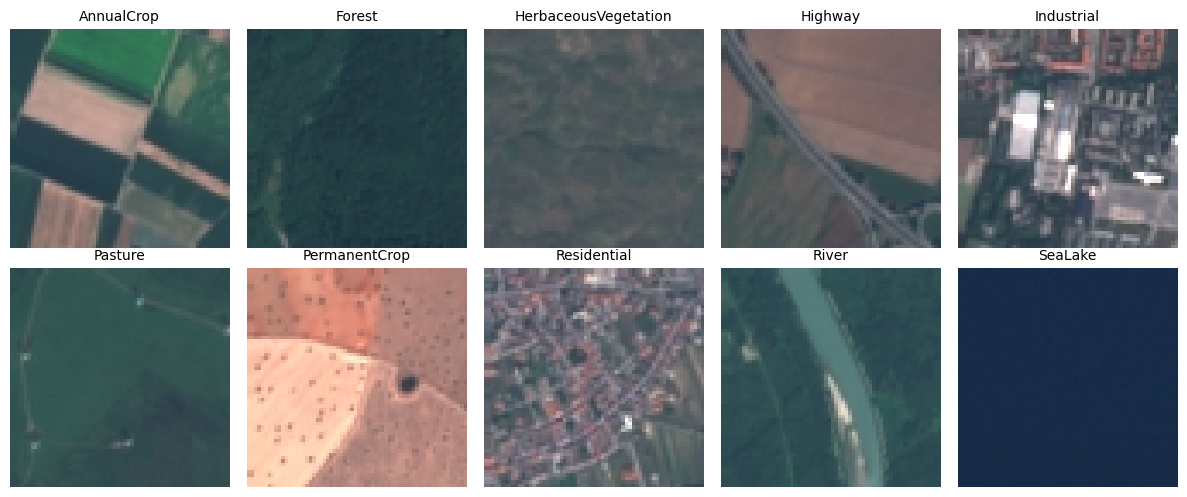

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for ax, clase in zip(axes.flat, clases):
    primera_img = next((ruta_dataset / clase).glob("*.jpg"))
    with Image.open(primera_img) as img:
        ax.imshow(img)
    ax.set_title(clase, fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.show()